In [1]:
pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'


In [2]:
import os
import json
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from datasets import load_dataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_class_weight

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")

np.random.seed(42)
tf.random.set_seed(42)

os.makedirs("data", exist_ok=True)
os.makedirs("artifacts", exist_ok=True)
os.makedirs("reports", exist_ok=True)

print("Project environment ready!")

c:\Users\Chandru\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project environment ready!


In [3]:
DATASET_NAME = (
    "Abdulmajeedyahya/"
    "1M-Fraud-Labeled-Synthetic-Bank-Transactions"
)

print("Loading banking transaction dataset...")

dataset = load_dataset(DATASET_NAME, split="train")

# Convert to pandas DataFrame
df = dataset.to_pandas()

# Use 5,000 records for this project
df = df.head(5000).copy()

# Save a local copy
df.to_csv("data/synthetic_sample_5k.csv", index=False)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print(df.head())

Loading banking transaction dataset...


Repo card metadata block was not found. Setting CardData to empty.


Dataset loaded successfully!
Dataset shape: (5000, 43)
                         transaction_id      customer_id   customer_segment  \
0  02d82794-f2a2-41f9-bce1-9cf95962a807  ACC384262F4DB19     SMALL_BUSINESS   
1  1ad78c7d-5ad1-47ed-9616-ac4f5b22e57c  ACCBB6DD861003C     SMALL_BUSINESS   
2  9e496ec9-a86c-488c-aa85-0d91dd19c966  ACC8A28288E8C78  FREQUENT_TRAVELER   
3  2b16f7e5-6abc-4f03-863e-63ddc1bb597b  ACCD2D5BAA7473E        MASS_RETAIL   
4  acab8f06-f271-4da0-b2c0-4cb89fe26dd6  ACC119C24334FEE        MASS_RETAIL   

  account_type transaction_timestamp transaction_date  transaction_hour  \
0       CREDIT   2022-01-01 00:50:47       2022-01-01                 0   
1       CREDIT   2022-01-01 01:08:26       2022-01-01                 1   
2     CHECKING   2022-01-01 01:47:42       2022-01-01                 1   
3     CHECKING   2022-01-01 01:49:04       2022-01-01                 1   
4       CREDIT   2022-01-01 02:02:02       2022-01-01                 2   

   transaction_dow 

Exploratory Data Analysis (EDA)


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 43 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   transaction_id           5000 non-null   str    
 1   customer_id              5000 non-null   str    
 2   customer_segment         5000 non-null   str    
 3   account_type             5000 non-null   str    
 4   transaction_timestamp    5000 non-null   str    
 5   transaction_date         5000 non-null   str    
 6   transaction_hour         5000 non-null   int64  
 7   transaction_dow          5000 non-null   int64  
 8   is_weekend               5000 non-null   int64  
 9   is_holiday               5000 non-null   int64  
 10  month                    5000 non-null   int64  
 11  quarter                  5000 non-null   int64  
 12  amount                   5000 non-null   float64
 13  currency                 5000 non-null   str    
 14  old_balance   

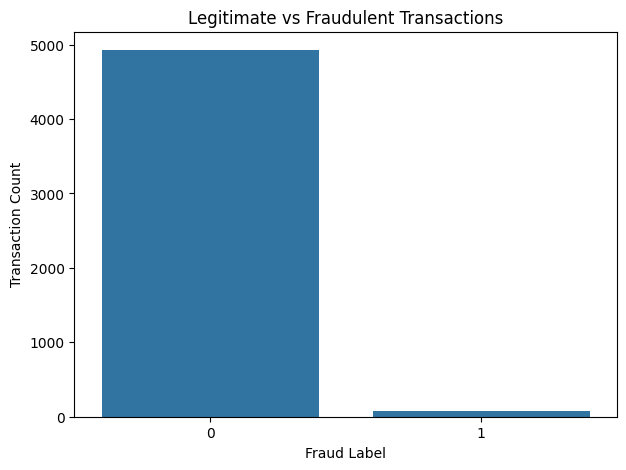

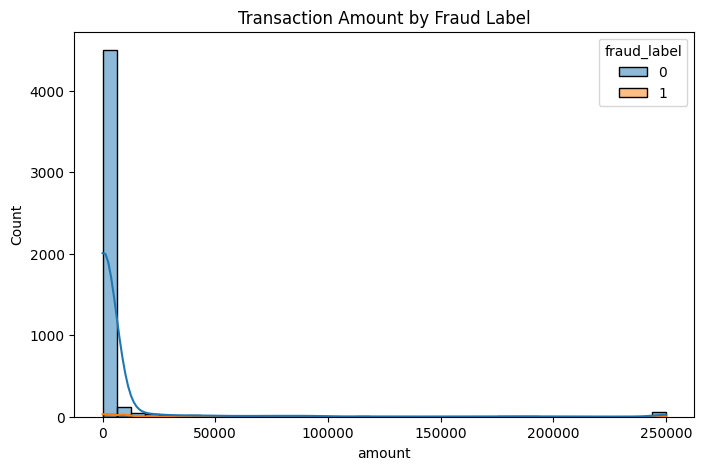

In [4]:
print("\nDATASET INFORMATION")

print(df.info())

print("\nFIRST FIVE RECORDS")

print(df.head())

print("\nSTATISTICAL SUMMARY")

print(df.describe(include="all").T)

print("\nMISSING VALUES")

print(df.isnull().sum())

print("\nDUPLICATE RECORDS")

print(df.duplicated().sum())


# Fraud distribution
print("\nFRAUD DISTRIBUTION")

print(df["fraud_label"].value_counts())

print("\nFRAUD PERCENTAGE")

print(
    df["fraud_label"]
    .value_counts(normalize=True) * 100
)


# Fraud distribution chart
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="fraud_label"
)

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Fraud Label")
plt.ylabel("Transaction Count")

plt.savefig("reports/fraud_distribution.png")
plt.show()


# Transaction amount distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="amount",
    hue="fraud_label",
    bins=40,
    kde=True
)

plt.title("Transaction Amount by Fraud Label")

plt.savefig("reports/transaction_amount.png")
plt.show()


DATA CLEANING AND LEAKAGE PREVENTION

In [5]:
# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Columns not used for model training
drop_columns = [
    "transaction_id",
    "customer_id",
    "merchant_name",
    "merchant_id",
    "device_id",
    "ip_address",
    "fraud_type",
    "chargeback_flag"
]

# Drop only columns that exist
df = df.drop(
    columns=drop_columns,
    errors="ignore"
)

# Ensure target is numeric
df["fraud_label"] = pd.to_numeric(
    df["fraud_label"],
    errors="coerce"
)

# Remove rows without target
df = df.dropna(subset=["fraud_label"])

df["fraud_label"] = df["fraud_label"].astype(int)

print("Cleaned dataset shape:", df.shape)
print("Remaining columns:", df.columns.tolist())

Cleaned dataset shape: (5000, 35)
Remaining columns: ['customer_segment', 'account_type', 'transaction_timestamp', 'transaction_date', 'transaction_hour', 'transaction_dow', 'is_weekend', 'is_holiday', 'month', 'quarter', 'amount', 'currency', 'old_balance', 'new_balance', 'balance_delta_check', 'mcc_code', 'mcc_category', 'merchant_sector', 'payment_rail', 'transaction_status', 'is_international', 'is_round_amount', 'device_type', 'device_os', 'trusted_device_count', 'new_device_flag', 'city', 'country', 'distance_from_home_km', 'credit_limit', 'credit_utilization', 'credit_score', 'account_age_days', 'transaction_velocity_1h', 'fraud_label']


FEATURE ENGINEERING

In [9]:
def engineer_features(data, amount_threshold=None):

    data = data.copy()

    # Feature 1: Balance change
    data["balance_change"] = (
        data["new_balance"] - data["old_balance"]
    )

    # Feature 2: Amount to balance ratio
    data["amount_balance_ratio"] = (
        data["amount"] /
        (data["old_balance"] + 1)
    )

    # Calculate high-value threshold if not supplied
    if amount_threshold is None:
        amount_threshold = data["amount"].quantile(0.95)

    # Feature 3: High-value transaction
    data["high_value_transaction"] = (
        data["amount"] >= amount_threshold
    ).astype(int)

    # Feature 4: Combined risk indicator
    risk_columns = [
        "is_international",
        "new_device_flag",
        "is_weekend",
        "is_holiday",
        "is_round_amount"
    ]

    data["risk_indicator"] = (
        data[risk_columns]
        .fillna(0)
        .astype(int)
        .sum(axis=1)
    )

    return data, amount_threshold


print("Feature engineering function created!")

print("Applying feature engineering...")

Feature engineering function created!
Applying feature engineering...


Feature selection

In [10]:
numeric_features = [

    "transaction_hour",
    "transaction_dow",
    "is_weekend",
    "is_holiday",
    "month",
    "quarter",
    "amount",
    "old_balance",
    "new_balance",
    "balance_change",
    "amount_balance_ratio",
    "is_international",
    "is_round_amount",
    "trusted_device_count",
    "new_device_flag",
    "distance_from_home_km",
    "credit_limit",
    "credit_utilization",
    "credit_score",
    "account_age_days",
    "transaction_velocity_1h",
    "high_value_transaction",
    "risk_indicator"
]


categorical_features = [

    "customer_segment",
    "account_type",
    "currency",
    "mcc_category",
    "merchant_sector",
    "payment_rail",
    "transaction_status",
    "device_type",
    "country"
]


features = numeric_features + categorical_features

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(features))

Numerical features: 23
Categorical features: 9
Total features: 32


TRAIN / VALIDATION / TEST SPLIT

In [11]:
# First separate input and target
# Create engineered columns before selecting model features
df, amount_threshold = engineer_features(df)

X_raw = df[features].copy()

y = df["fraud_label"].copy()

# First split: 70% training, 30% temporary
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_raw,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% testing
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training records:", len(X_train_raw))
print("Validation records:", len(X_val_raw))
print("Testing records:", len(X_test_raw))

Training records: 3500
Validation records: 750
Testing records: 750


Preprocessing

In [12]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_pipeline,
            numeric_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train_raw)

# Transform validation and test data
X_val_processed = preprocessor.transform(X_val_raw)

X_test_processed = preprocessor.transform(X_test_raw)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)
print("Testing shape:", X_test_processed.shape)

print(
    "Processed feature count:",
    len(preprocessor.get_feature_names_out())
)

Training shape: (3500, 122)
Validation shape: (750, 122)
Testing shape: (750, 122)
Processed feature count: 122


Class imbalance handling

In [13]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(
    zip(classes, weights)
)

print("Class weights:", class_weights)

Class weights: {np.int64(0): np.float64(0.5073934473760511), np.int64(1): np.float64(34.31372549019608)}


Logistic Regression baseline

In [14]:
baseline_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

baseline_model.fit(
    X_train_processed,
    y_train
)

# Test predictions
baseline_probability = baseline_model.predict_proba(
    X_test_processed
)[:, 1]

baseline_prediction = (
    baseline_probability >= 0.50
).astype(int)

print("\nLOGISTIC REGRESSION RESULTS")

print(
    classification_report(
        y_test,
        baseline_prediction,
        zero_division=0
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, baseline_probability)
)

print(
    "PR-AUC:",
    average_precision_score(y_test, baseline_probability)
)


LOGISTIC REGRESSION RESULTS
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       739
           1       0.41      0.82      0.55        11

    accuracy                           0.98       750
   macro avg       0.70      0.90      0.77       750
weighted avg       0.99      0.98      0.98       750

ROC-AUC: 0.9880674129659245
PR-AUC: 0.8136986301369864


Deep Neural Network

In [15]:
input_dimension = X_train_processed.shape[1]

model = Sequential([

    Input(shape=(input_dimension,)),

    Dense(128, activation="relu"),

    Dropout(0.30),

    Dense(64, activation="relu"),

    Dropout(0.20),

    Dense(32, activation="relu"),

    Dense(1, activation="sigmoid")

])

model.summary()


# Compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)


# Early stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)


# Train model
history = model.fit(
    X_train_processed,
    y_train,

    validation_data=(
        X_val_processed,
        y_val
    ),

    epochs=50,
    batch_size=32,

    class_weight=class_weights,

    callbacks=[early_stopping],

    verbose=1
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        15,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,113 (102.00 KB)

 Trainable params: 26,113 (102.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9349 - loss: 0.5448 - precision: 0.1031 - recall: 0.4510 - val_accuracy: 0.9907 - val_loss: 0.2151 - val_precision: 0.6667 - val_recall: 0.7273
Epoch 2/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9540 - loss: 0.3785 - precision: 0.1944 - recall: 0.6863 - val_accuracy: 0.9653 - val_loss: 0.2137 - val_precision: 0.2581 - val_recall: 0.7273
Epoch 3/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9537 - loss: 0.2795 - precision: 0.2183 - recall: 0.8431 - val_accuracy: 0.9693 - val_loss: 0.1669 - val_precision: 0.2857 - val_recall: 0.7273
Epoch 4/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9654 - loss: 0.1811 - precision: 0.2812 - recall: 0.8824 - val_accuracy: 0.9707 - val_loss: 0.1182 - val_precision: 0.2963 - val_recall: 0.7273
Epoch 5/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9614 - loss: 0.1416 - precision: 0.2640 - recall: 0.9216 - val_accuracy: 0.9627 - val_loss: 0.

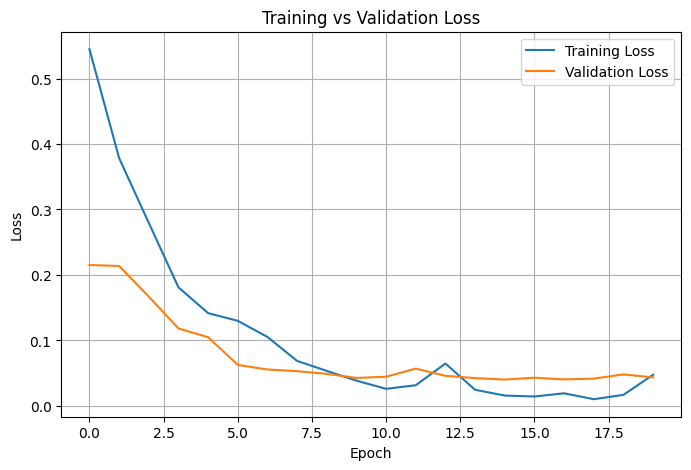

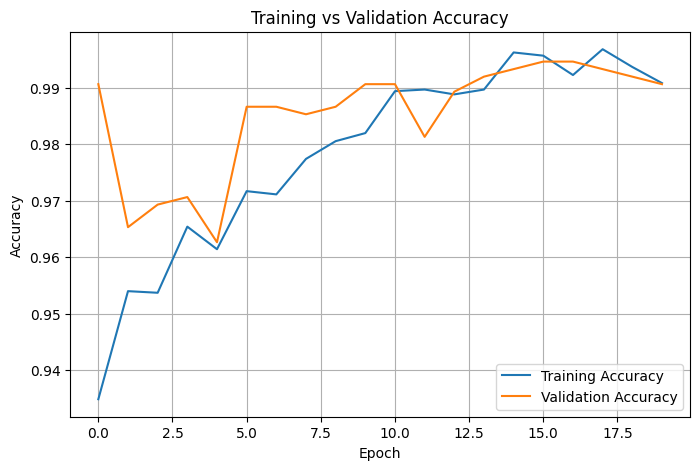

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig("reports/training_loss.png")
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.savefig("reports/training_accuracy.png")
plt.show()

Threshold tuning using validation data

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
    threshold  precision    recall        f1
0        0.10   0.500000  0.727273  0.592593
1        0.15   0.500000  0.727273  0.592593
2        0.20   0.533333  0.727273  0.615385
3        0.25   0.615385  0.727273  0.666667
4        0.30   0.615385  0.727273  0.666667
5        0.35   0.727273  0.727273  0.727273
6        0.40   0.727273  0.727273  0.727273
7        0.45   0.800000  0.727273  0.761905
8        0.50   0.800000  0.727273  0.761905
9        0.55   0.777778  0.636364  0.700000
10       0.60   0.777778  0.636364  0.700000
11       0.65   0.777778  0.636364  0.700000
12       0.70   0.777778  0.636364  0.700000
13       0.75   0.875000  0.636364  0.736842
14       0.80   0.875000  0.636364  0.736842
15       0.85   0.875000  0.636364  0.736842
16       0.90   0.875000  0.636364  0.736842

Selected threshold: 0.45000000000000007


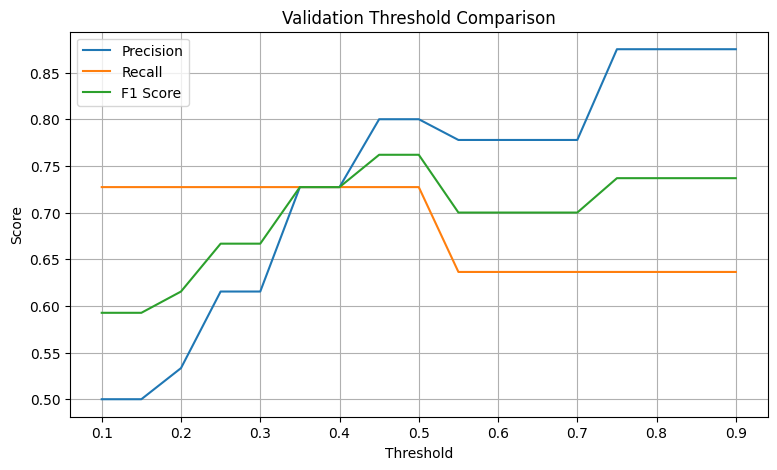

In [17]:
# Get validation probabilities
val_probability = model.predict(
    X_val_processed
).ravel()

threshold_results = []

thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

for threshold in thresholds:

    val_prediction = (
        val_probability >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        val_prediction,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        val_prediction,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        val_prediction,
        zero_division=0
    )

    threshold_results.append({
        "threshold": float(threshold),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1)
    })


threshold_df = pd.DataFrame(threshold_results)

print(threshold_df)

# Select threshold with best validation F1
best_row = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

best_threshold = float(
    best_row["threshold"]
)

print("\nSelected threshold:", best_threshold)

threshold_df.to_csv(
    "reports/threshold_comparison.csv",
    index=False
)

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    label="F1 Score"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Validation Threshold Comparison")
plt.legend()
plt.grid(True)

plt.savefig("reports/threshold_comparison.png")
plt.show()


Final test evaluation

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 

FINAL DEEP LEARNING RESULTS
threshold : 0.45
accuracy : 0.984
precision : 0.4286
recall : 0.2727
f1 : 0.3333
roc_auc : 0.9167
pr_auc : 0.3696

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       739
           1       0.43      0.27      0.33        11

    accuracy                           0.98       750
   macro avg       0.71      0.63      0.66       750
weighted avg       0.98      0.98      0.98       750



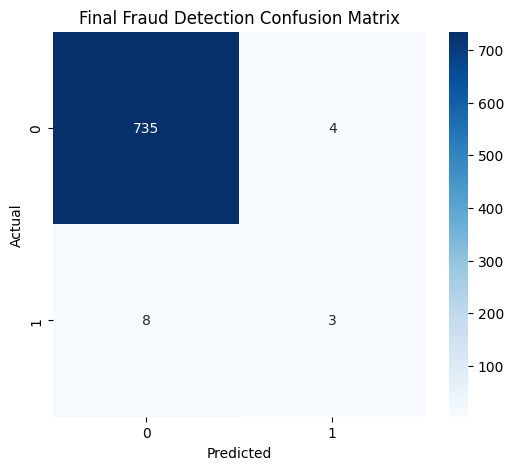

In [18]:
test_probability = model.predict(
    X_test_processed
).ravel()

test_prediction = (
    test_probability >= best_threshold
).astype(int)


accuracy = accuracy_score(
    y_test,
    test_prediction
)

precision = precision_score(
    y_test,
    test_prediction,
    zero_division=0
)

recall = recall_score(
    y_test,
    test_prediction,
    zero_division=0
)

f1 = f1_score(
    y_test,
    test_prediction,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    test_probability
)

pr_auc = average_precision_score(
    y_test,
    test_probability
)

metrics = {
    "threshold": best_threshold,
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1": float(f1),
    "roc_auc": float(roc_auc),
    "pr_auc": float(pr_auc)
}

print("\nFINAL DEEP LEARNING RESULTS")

for key, value in metrics.items():
    print(key, ":", round(value, 4))


print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        test_prediction,
        zero_division=0
    )
)


# Confusion matrix
cm = confusion_matrix(
    y_test,
    test_prediction
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Final Fraud Detection Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig("reports/confusion_matrix.png")
plt.show()


# Save metrics
with open(
    "reports/model_metrics.json",
    "w"
) as f:

    json.dump(metrics, f, indent=4)


# Save test predictions for dashboard
results_df = X_test_raw.copy()

results_df["actual_fraud_label"] = y_test.values

results_df["fraud_probability"] = test_probability

results_df["predicted_fraud"] = test_prediction

results_df["risk_score"] = test_probability * 100

results_df.to_csv(
    "reports/test_predictions.csv",
    index=False
)

SHAP explainability

PermutationExplainer explainer: 51it [00:25,  1.61it/s]                        


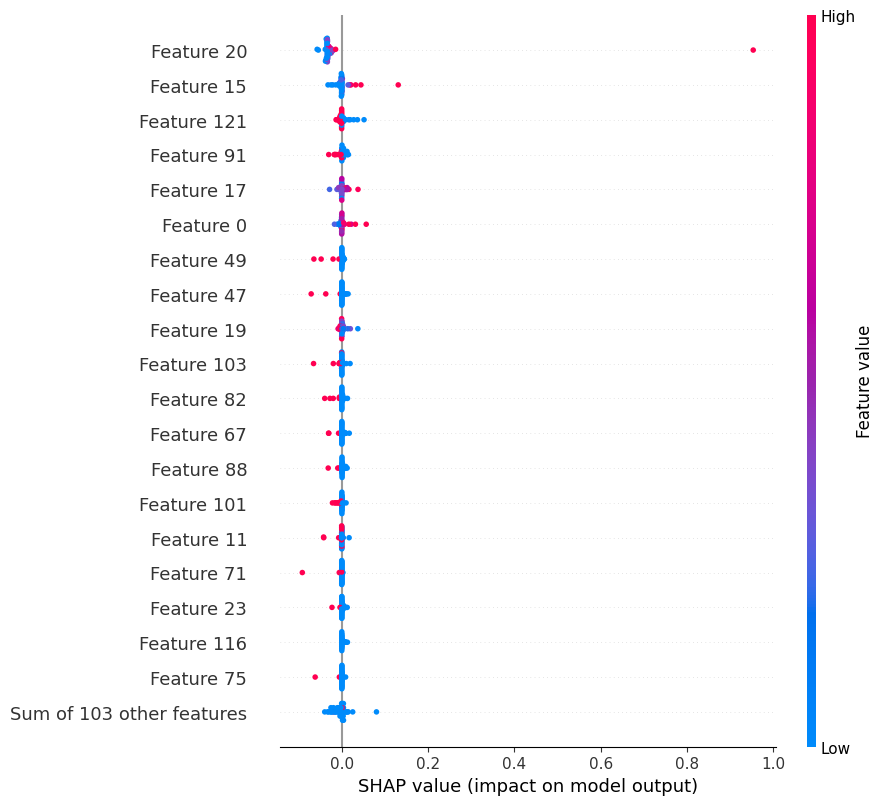

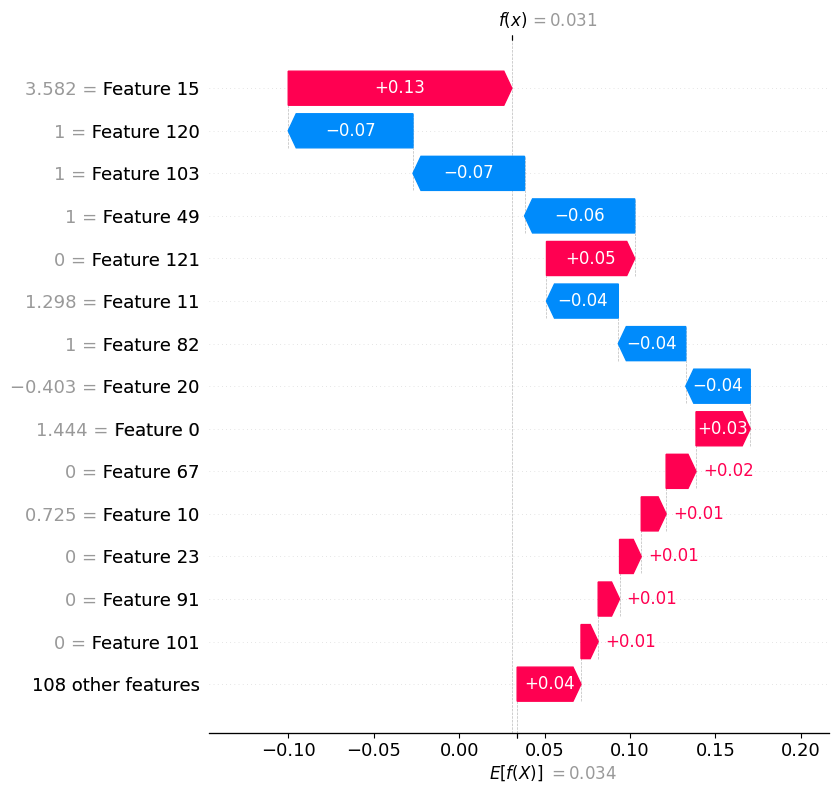

In [19]:
import shap

# Small samples keep the explanation calculation manageable
background_size = min(30, len(X_train_processed))
explanation_size = min(50, len(X_test_processed))

background_data = X_train_processed[:background_size]

explanation_data = X_test_processed[:explanation_size]

# Explain model predictions
explainer = shap.Explainer(
    lambda values: model.predict(
        np.asarray(values, dtype=np.float32),
        verbose=0
    ).ravel(),
    background_data
)

shap_values = explainer(explanation_data)

# Global explanation
shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

plt.savefig(
    "reports/shap_beeswarm.png",
    bbox_inches="tight"
)

plt.show()


# Individual explanation
shap.plots.waterfall(
    shap_values[0],
    max_display=15,
    show=False
)

plt.savefig(
    "reports/shap_waterfall.png",
    bbox_inches="tight"
)

plt.show()

Risk scoring

In [20]:
def get_risk_level(score):

    if score < 30:
        return "Low"

    elif score < 60:
        return "Medium"

    elif score < 80:
        return "High"

    else:
        return "Critical"


results_df["risk_level"] = (
    results_df["risk_score"]
    .apply(get_risk_level)
)

print(
    results_df[
        [
            "fraud_probability",
            "risk_score",
            "risk_level"
        ]
    ].head()
)

results_df.to_csv(
    "reports/test_predictions.csv",
    index=False
)


      fraud_probability  risk_score risk_level
4523           0.030836    3.083556        Low
2827           0.000111    0.011114        Low
3627           0.000046    0.004582        Low
3146           0.004009    0.400876        Low
402            0.001477    0.147723        Low


In [23]:
model.save(
    "artifacts/fraud_detection_model.keras"
)

# Save preprocessing object
joblib.dump(
    preprocessor,
    "artifacts/preprocessor.pkl"
)

# Save threshold
with open(
    "artifacts/threshold.json",
    "w"
) as f:

    json.dump(
        {"threshold": best_threshold},
        f,
        indent=4
    )


# Save feature metadata
metadata = {

    "numeric_features": numeric_features,

    "categorical_features": categorical_features,

    "all_features": features,

    "processed_feature_count": int(
        X_train_processed.shape[1]
    ),

    "risk_levels": {
        "low": "<30",
        "medium": "30 to <60",
        "high": "60 to <80",
        "critical": "80 and above"
    },

    "dataset": DATASET_NAME,

    "sample_size": len(df)
}

with open(
    "artifacts/metadata.json",
    "w"
) as f:

    json.dump(metadata, f, indent=4)


# Save baseline model too
joblib.dump(
    baseline_model,
    "artifacts/logistic_regression.pkl"
)

print("\nALL MODEL ARTIFACTS SAVED SUCCESSFULLY!")


ALL MODEL ARTIFACTS SAVED SUCCESSFULLY!
